IMPORTING PACKAGES

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing
from sklearn.impute import SimpleImputer
from matplotlib import pyplot as plt #data visualization
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler


LOADING DATA

Load the data of the csv file containing Netflix's customer churn information.
The file contains attributes such as customer ID, age, gender, subscription type, watch hours, last login date and more.    

In [7]:
X = pd.read_csv('/Users/wiegerhelsdingen/Documents/Github/netflix-churn-prediction/src/netflix_customer_churn.csv')

DATA DICTIONARY

Source: Kaggle, [Netflix Customer Churn dataset](https://www.kaggle.com/datasets/abdulwadood11220/netflix-customer-churn-dataset) by Abdul Wadood (version 1, July 2025, CC BY-SA 4.0). 5,000 rows, 14 columns.

**The data is synthetic.** The dataset description says it simulates customer behaviour for a Netflix-like streaming service. It is not real Netflix data.

The dataset page gives no column definitions and doesn't say how `churned` was generated. The meanings below are our interpretation of the column names, checked against the data where possible.

| Column | Type | Values in this file | Interpretation | Notes |
|---|---|---|---|---|
| `customer_id` | text | unique ID | Anonymous customer ID | Not a feature, drop before modelling |
| `age` | int | 18 – 70 | Age in years | |
| `gender` | category | Female, Male, Other | Gender | |
| `subscription_type` | category | Basic, Standard, Premium | Current plan | |
| `watch_hours` | float | 0.01 – 110.4 | Total streaming hours | Time period not defined |
| `last_login_days` | int | 0 – 60 | Days since last login | Possible leakage, see the leakage analysis |
| `region` | category | 6 continents | Customer's region | |
| `device` | category | Desktop, Laptop, Mobile, TV, Tablet | Main viewing device | |
| `monthly_fee` | float | 8.99, 13.99, 17.99 | Monthly price | Fully determined by `subscription_type` |
| `churned` | int | 0 / 1 | **Target**: 1 = customer churned | How it was generated isn't documented |
| `payment_method` | category | 5 methods | Payment method | |
| `number_of_profiles` | int | 1 – 5 | Viewer profiles on the account | |
| `avg_watch_time_per_day` | float | 0.00 – 98.42 | Average daily watch time | Verified from the data: `watch_hours / (last_login_days + 1)`, rounded to 2 decimals |
| `favorite_genre` | category | 7 genres | Most-watched genre | |

CLEANING DATA

First separate target from the dataset (y).
Then check if there are any missing values & in what column they are missing. 
We also check the type of each column.
Then we split the data into numerical and categorical values. Let's convert all numerical values in to floats or integers and convert all categorical values to type category.

In [9]:
# Check for missing values
missing_values = X.isnull().sum()
print('Missing values in each column:')
print(missing_values)

# Data Types
print('\nData types:')
print(X.dtypes)


# Remove rows with missing target, separate target from predictors
X.dropna(axis=0, subset=['churned'], inplace=True)
y = X.churned
X.drop(['churned'], axis=1, inplace=True)

# remove duplicate rows
X = X.drop_duplicates()

# Split the dataset into categorical and numeric columns
categorical_columns = ['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']
for col in categorical_columns:
    X[col] = X[col].astype('category')
X_cat = X[categorical_columns].copy()

print('\nCategorical columns:')
print(categorical_columns)

numeric_columns = ['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']
for col in numeric_columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')
X_num = X[numeric_columns].copy()

print('\nNumeric columns:')
print(numeric_columns)



Missing values in each column:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Data types:
customer_id                    str
age                          int64
gender                    category
subscription_type         category
watch_hours                float64
last_login_days              int64
region                    category
device                    category
monthly_fee                float64
payment_method            category
number_of_profiles           int64
avg_watch_time_per_day     float64
favorite_genre            category
dtype: object


KeyError: ['churned']

EXPLORATORY DATA ANALYSIS - NUMERICAL VALUES

Feature distributions

Age, last login days, monthly fee and number of profiles are uniformly distributed, looking at the histogram and box plots.
Watch hours and avg watch time per day show a highly skewed normal distribution, making it worthwily to check for outliers.

Outliers

Outliers seem to be within sanity bounds. However, since avg watch time per day only has 2 examples higher than 40, let's clip this feature at 40.

Target 

Churned labels are well balanced, around 50/50, so we can work with accuracy as evaluation metric.
Now the question: What is more costly, a false postive or a false negative?
Thinking about the business, we want to know if a customer churns before they do to avoid paying more for reactivating them. Missing a churning customor (FN) costs us an expensive reactivation campaign. Incorrectly identifying a churning customer costs us a cheaper retention campaign (FP). FN is more costly, thus let's add recall as evaluation metric.
Since the model output will be a probability (value between 0 and 1) I'd also add AUC as evaluation metric.

Feature-target correlation
looing at the boxplots and histograms, watch hours, watch hours per day and last login days have a high correlation with the target. In the next module we'll verify if there is any leakage from any of these features. Number of profiles also seems to influence churn. Low number (<3) clearly has higher churn rates.


Cross-correlation between features

Then, looking at the correlation matrix, we see that watch hours and avg watch time per day have a high correlation. This could cause instability if we include both features in our model. Given that watch hours has the highest correlation with churned, we'll include only this feature.

Conclusion:
We'll onlly keep last login days, watch time per day and number of profiles as features.

                         count      mean        std    min      25%    50%  \
age                     5000.0  43.84740  15.501128  18.00  30.0000  44.00   
watch_hours             5000.0  11.64945  12.014654   0.01   3.3375   8.00   
last_login_days         5000.0  30.08980  17.536078   0.00  15.0000  30.00   
monthly_fee             5000.0  13.68340   3.692062   8.99   8.9900  13.99   
number_of_profiles      5000.0   3.02440   1.415841   1.00   2.0000   3.00   
avg_watch_time_per_day  5000.0   0.87480   2.619824   0.00   0.1100   0.29   

                          75%     max  
age                     58.00   70.00  
watch_hours             16.03  110.40  
last_login_days         45.00   60.00  
monthly_fee             17.99   17.99  
number_of_profiles       4.00    5.00  
avg_watch_time_per_day   0.72   98.42  


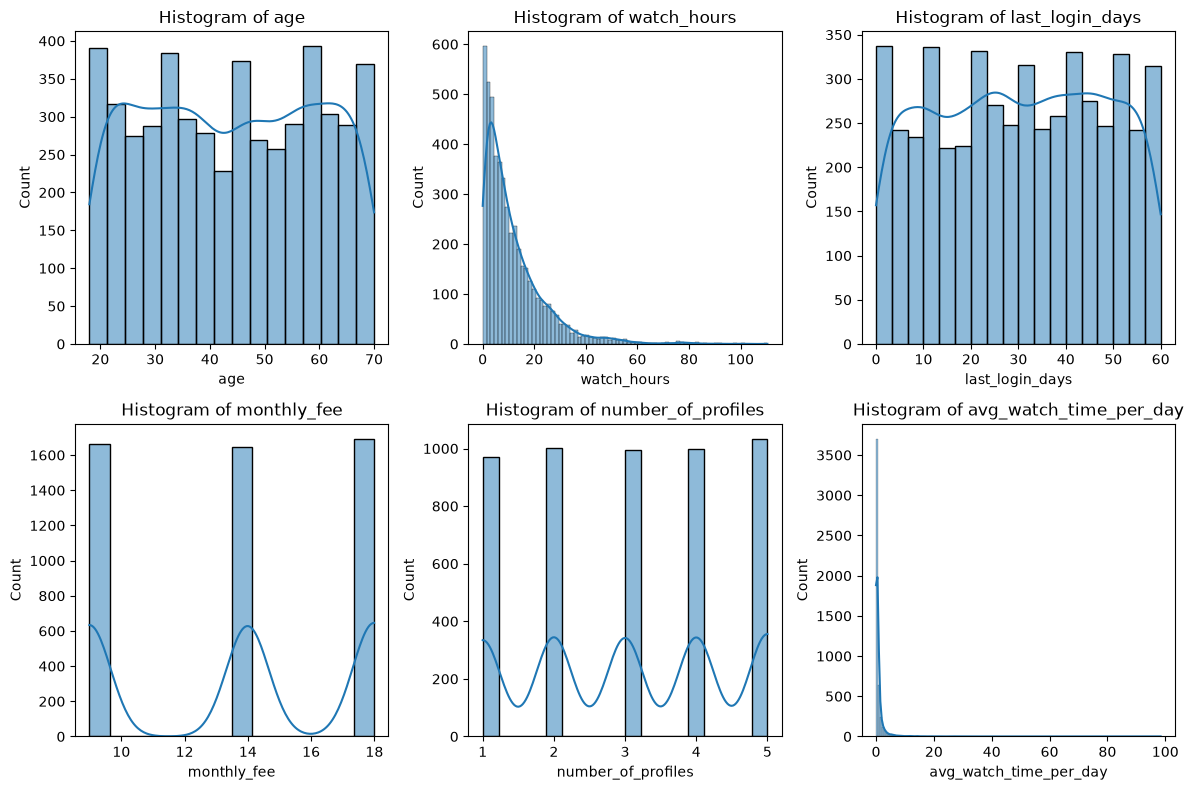

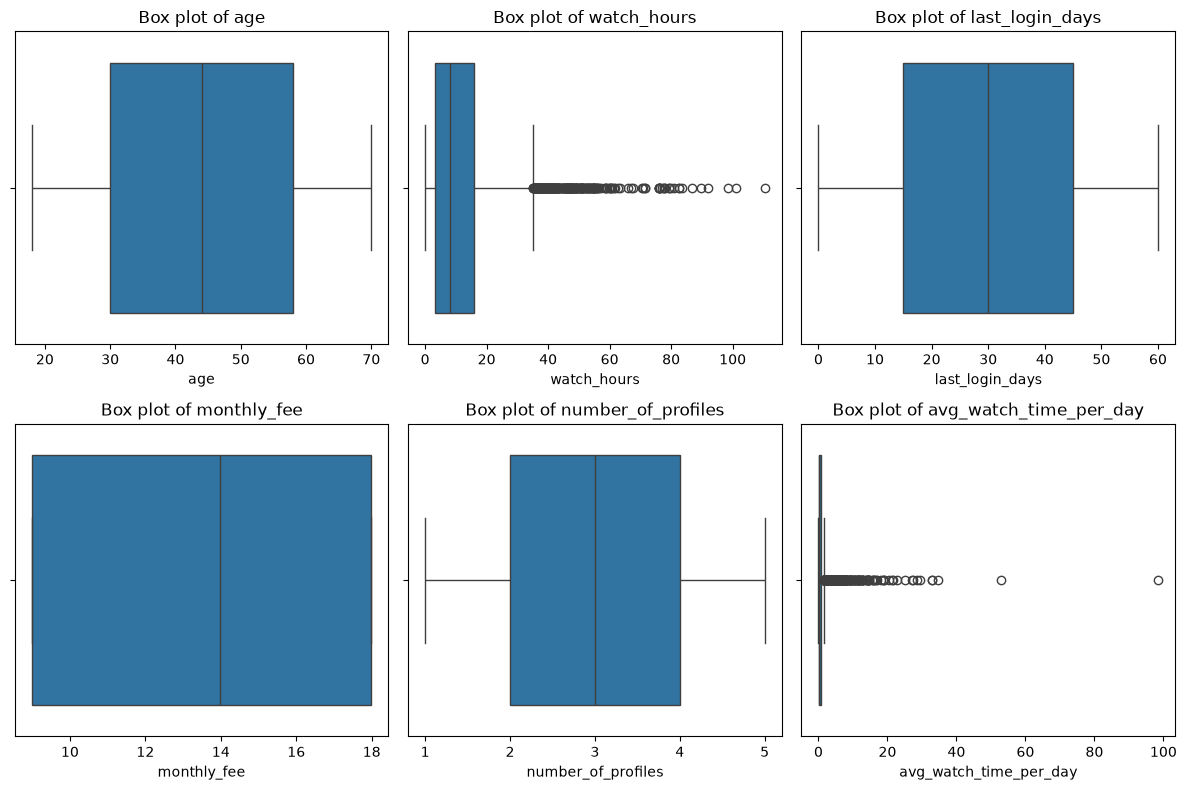

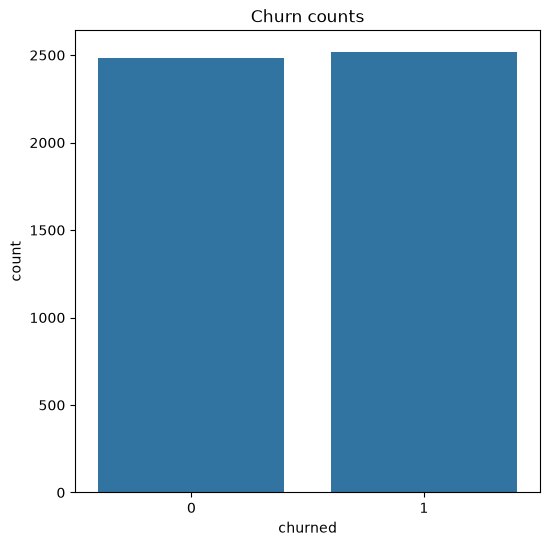

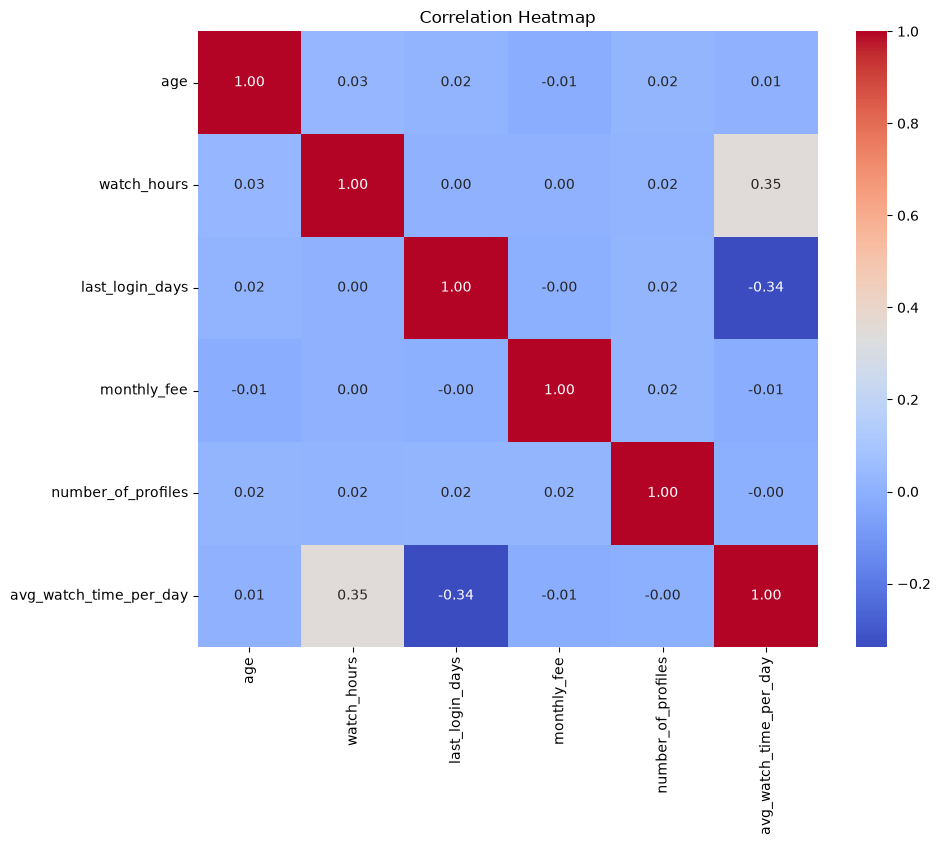

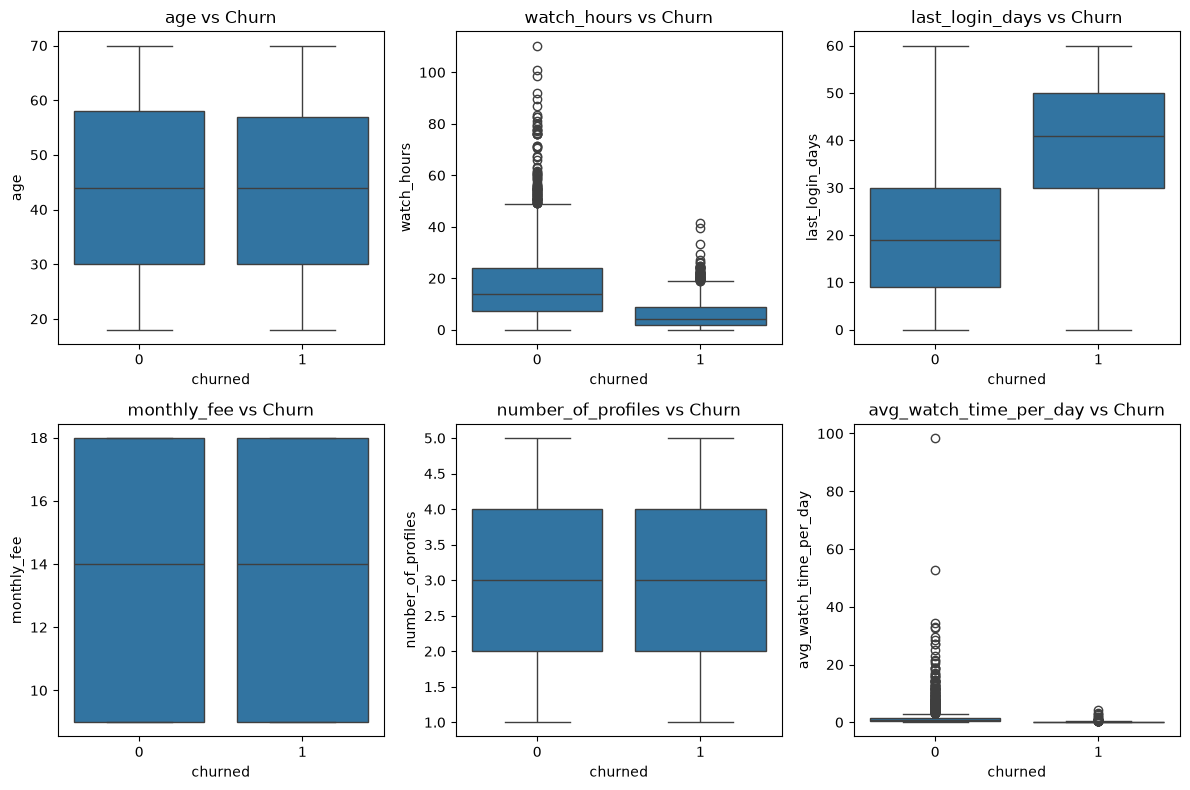

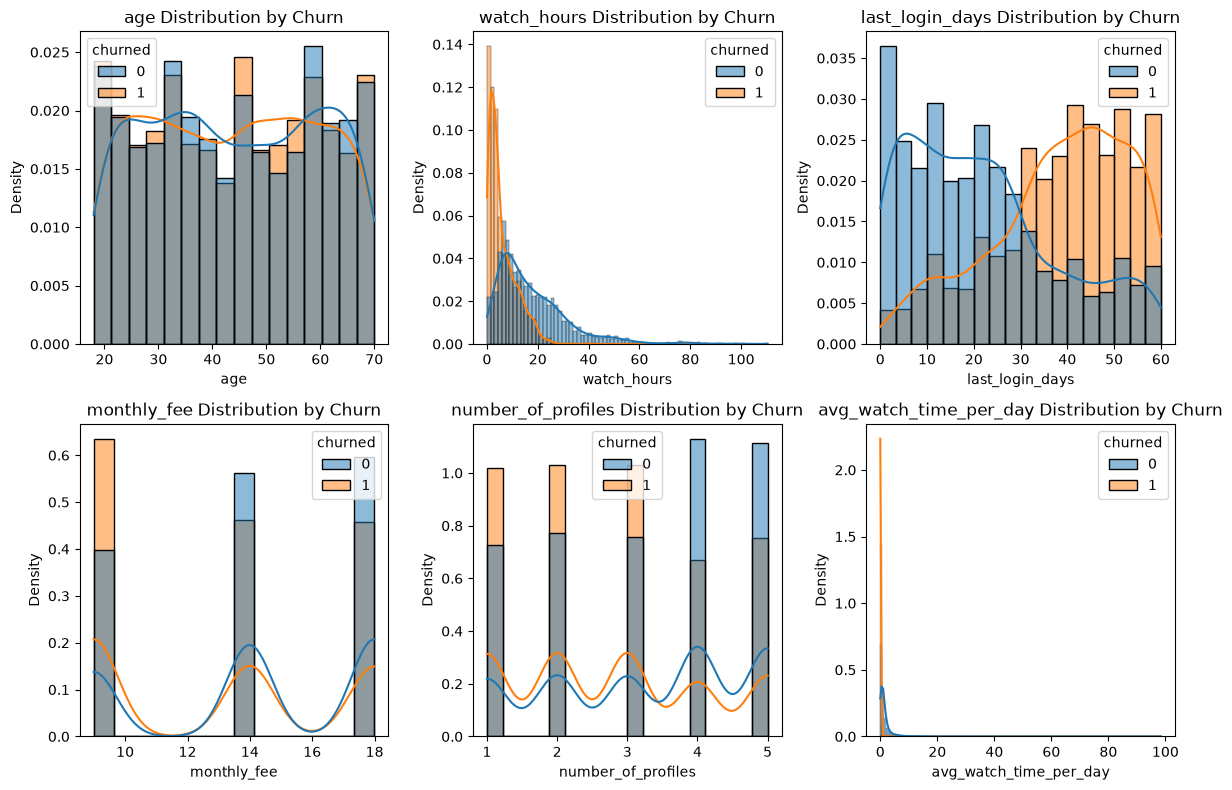

                  Feature  Churned Median  Not Churned Median        p-value
1             watch_hours            4.06               13.86   0.000000e+00
5  avg_watch_time_per_day            0.12                0.72   0.000000e+00
2         last_login_days           41.00               19.00  1.878447e-243
4      number_of_profiles            3.00                3.00   3.471228e-29
3             monthly_fee           13.99               13.99   1.417874e-25
0                     age           44.00               44.00   7.802933e-01


In [11]:
# Statistical summary of numeric columns
print(X[numeric_columns].describe().T)

# Histogram for numeric columns
plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(X[col], kde=True)
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.show()

# Box plots to check for outliers in numeric data
plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=X[col])
    plt.title(f'Box plot of {col}')
plt.tight_layout()
plt.show()

# Pie chart for churned vs non-churned
plt.figure(figsize=(6, 6))
churn_counts = y.value_counts()
sns.countplot(x=y)
plt.title('Churn counts')
plt.show()

# # Pair plot of numeric features if there are at least 4
# sns.pairplot(X[numeric_columns])

# Correlation heatmap of numeric columns (if at least 4 are present)
if X_num.shape[1] >= 4:
    plt.figure(figsize=(10, 8))
    corr = X_num.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.show()


# Numerical features vs churn
plt.figure(figsize=(12, 8))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=pd.DataFrame({
            col: X[col],
            'churned': y
        }),
        x='churned',
        y=col
    )

    plt.title(f'{col} vs Churn')

plt.tight_layout()
plt.show()

# Distribution of numerical features by churn
plt.figure(figsize=(12, 8))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)

    sns.histplot(
        data=pd.DataFrame({
            col: X[col],
            'churned': y
        }),
        x=col,
        hue='churned',
        kde=True,
        stat='density',
        common_norm=False
    )

    plt.title(f'{col} Distribution by Churn')

plt.tight_layout()
plt.show()



from scipy.stats import mannwhitneyu

results = []

for col in numeric_columns:

    churned = X.loc[y == 1, col].dropna()
    not_churned = X.loc[y == 0, col].dropna()

    statistic, p_value = mannwhitneyu(
        churned,
        not_churned,
        alternative='two-sided'
    )

    results.append({
        'Feature': col,
        'Churned Median': churned.median(),
        'Not Churned Median': not_churned.median(),
        'p-value': p_value
    })

numerical_tests = pd.DataFrame(results)

print(numerical_tests.sort_values('p-value'))




LEAKAGE ANALYSIS

Question: do `last_login_days`, `watch_hours` and avg_watch_time_per_day predict churn, or do they describe churn that already happened?

Approach:
A customer who cancelled 40 days ago also hasn't logged in for 40 days. If that's what drives the pattern, the feature is a consequence of churn, not an early warning sign, and the model would look great on paper but be useless in practice.

What we'd expect to see:
- Churn is likely defined as canceling your subscription, which means that there would be no leakage.
- **Leaky:** churn rate jumps to (almost) 100% above some number of days, because churned customers simply stopped logging in.
- **Genuine signal:** churn rate rises gradually as days since last login go up, and never reaches 100%.

As the dataset has no dates and there is no definition of churn, we can't prove it either way, so we're looking for clues:
1. Churn rate per band of `last_login_days` and `watch_hours`
2. Churn rate for combinations of the two
3. How well each feature separates churners on its own (AUC of a single feature)


Findings:

- **No clear leakage.** Churn among customers who haven't logged in for 40–60 days levels off at ~75%. It never reaches 100%, so it isn't simply "churned customers stop logging in".
- **But there's a sharp step at 30 days.** Churn jumps from ~35% (21–30 days) to ~72% (31–40 days). I expect this is due to the fact that when customers cancel their subscription, they need to wait until the month is finished.
- `watch_hours` shows similar steps at 5 and 20 hours. Real customer behaviour usually changes gradually, so this suggests the dataset was generated with rules like "inactive for more than 30 days → higher chance of churn". Another reason to list "probably synthetic data" as a limitation.
- **Combined, the two features are very strong.** Customers with fewer than 5 watch hours who haven't logged in for 40+ days churned 100% of the time.
- `avg_watch_time_per_day` separates churners best on its own (AUC 0.92), because it combines both features: it equals `watch_hours / (last_login_days + 1)`.

Decision: keep `last_login_days`, and log it as a leakage risk. In model development, train one model with it and one without, to see how much performance depends on it. In a real project we'd ask the data owner how and when `churned` was recorded.

avg_watch_time_per_day == watch_hours / (last_login_days + 1) for 100.0% of rows

Churn rate by days since last login:
                 churn_rate  customers
last_login_days                       
(-1, 10]               0.17        907
(10, 20]               0.27        775
(20, 30]               0.35        849
(30, 40]               0.73        822
(40, 50]               0.78        843
(50, 60]               0.75        804

Churn rate by watch hours:
             churn_rate  customers
watch_hours                       
(-1, 2]            0.86        810
(2, 5]             0.83        960
(5, 10]            0.44       1150
(10, 20]           0.40       1197
(20, 40]           0.05        711
(40, 200]          0.01        172

Churn rate by avg watch time per day:
                        churn_rate  customers
avg_watch_time_per_day                       
(-0.01, 0.1]                  0.94       1188
(0.1, 0.25]                   0.77       1100
(0.25, 0.5]                   0.51    

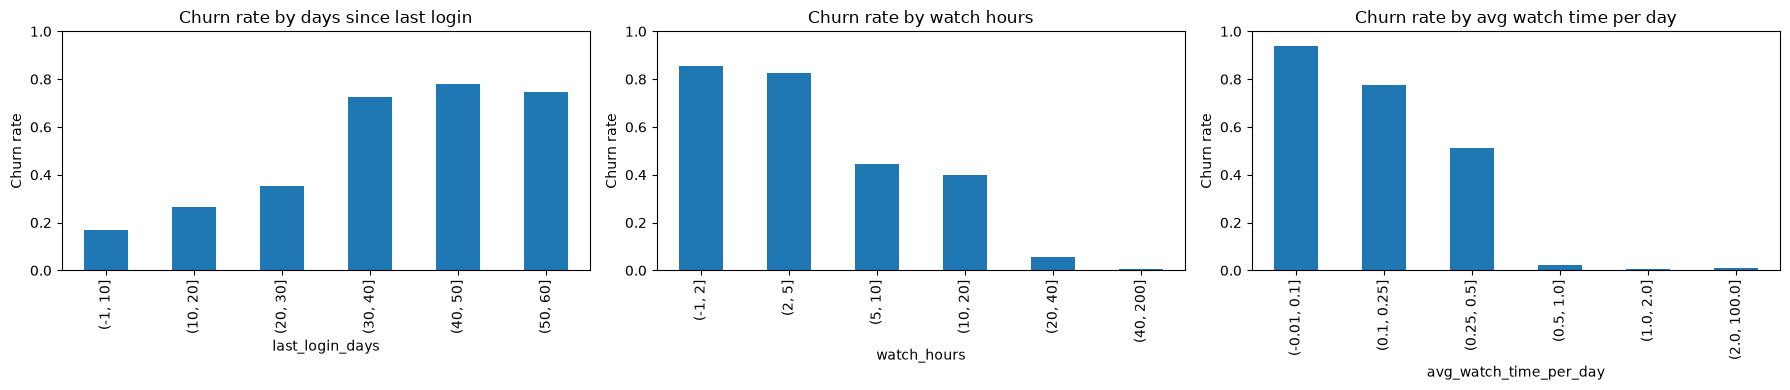

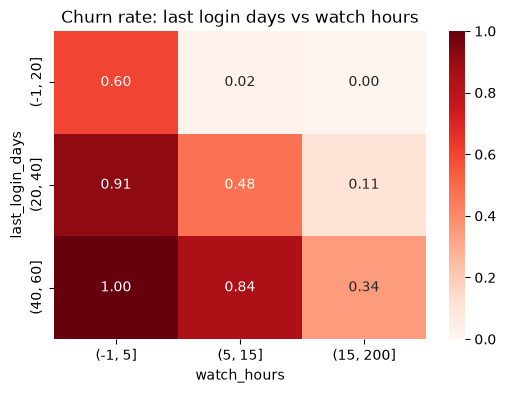

last_login_days           AUC on its own: 0.772
watch_hours               AUC on its own: 0.813
avg_watch_time_per_day    AUC on its own: 0.924


In [14]:
from sklearn.metrics import roc_auc_score

# 0. Check how avg_watch_time_per_day is calculated.
# The dataset doesn't document it; this formula matches every row (up to rounding to 2 decimals)
calculated = X['watch_hours'] / (X['last_login_days'] + 1)
matches = (calculated.round(2) - X['avg_watch_time_per_day']).abs() <= 0.011
print(f'avg_watch_time_per_day == watch_hours / (last_login_days + 1) for {matches.mean():.1%} of rows\n')

# 1. Churn rate per band (the mean of a 0/1 column is the proportion of 1s)
login_bands = pd.cut(X['last_login_days'], bins=[-1, 10, 20, 30, 40, 50, 60])
watch_bands = pd.cut(X['watch_hours'], bins=[-1, 2, 5, 10, 20, 40, 200])
avg_bands = pd.cut(X['avg_watch_time_per_day'], bins=[-0.01, 0.1, 0.25, 0.5, 1, 2, 100])

login_churn = y.groupby(login_bands, observed=True).agg(churn_rate='mean', customers='size')
watch_churn = y.groupby(watch_bands, observed=True).agg(churn_rate='mean', customers='size')
avg_churn = y.groupby(avg_bands, observed=True).agg(churn_rate='mean', customers='size')
print('Churn rate by days since last login:')
print(login_churn.round(2))
print('\nChurn rate by watch hours:')
print(watch_churn.round(2))
print('\nChurn rate by avg watch time per day:')
print(avg_churn.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
login_churn['churn_rate'].plot(kind='bar', ax=axes[0], title='Churn rate by days since last login')
watch_churn['churn_rate'].plot(kind='bar', ax=axes[1], title='Churn rate by watch hours')
avg_churn['churn_rate'].plot(kind='bar', ax=axes[2], title='Churn rate by avg watch time per day')
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel('Churn rate')
plt.tight_layout()
plt.show()

# 2. Churn rate for combinations of both features
combo = pd.crosstab(
    pd.cut(X['last_login_days'], bins=[-1, 20, 40, 60]),
    pd.cut(X['watch_hours'], bins=[-1, 5, 15, 200]),
    values=y,
    aggfunc='mean'
)
plt.figure(figsize=(6, 4))
sns.heatmap(combo, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Churn rate: last login days vs watch hours')
plt.show()

# 3. How well does each feature separate churners on its own?
# AUC = 0.5 means no better than guessing, 1.0 means perfect separation
for col in ['last_login_days', 'watch_hours', 'avg_watch_time_per_day']:
    auc = roc_auc_score(y, X[col])
    print(f'{col:25s} AUC on its own: {max(auc, 1 - auc):.3f}')

EXPORATORY DATA ANALYSIS - CATEGORICAL VALUES

Here we plot the churn rate for each category directly, with the overall churn rate as a dotted line. Bars that stick out above or below the line are the categories that matter. The only values that stick out and thus seem to correlate with churn are payment method and subscription type.

Decision: only keep payment method and subscription type as features.

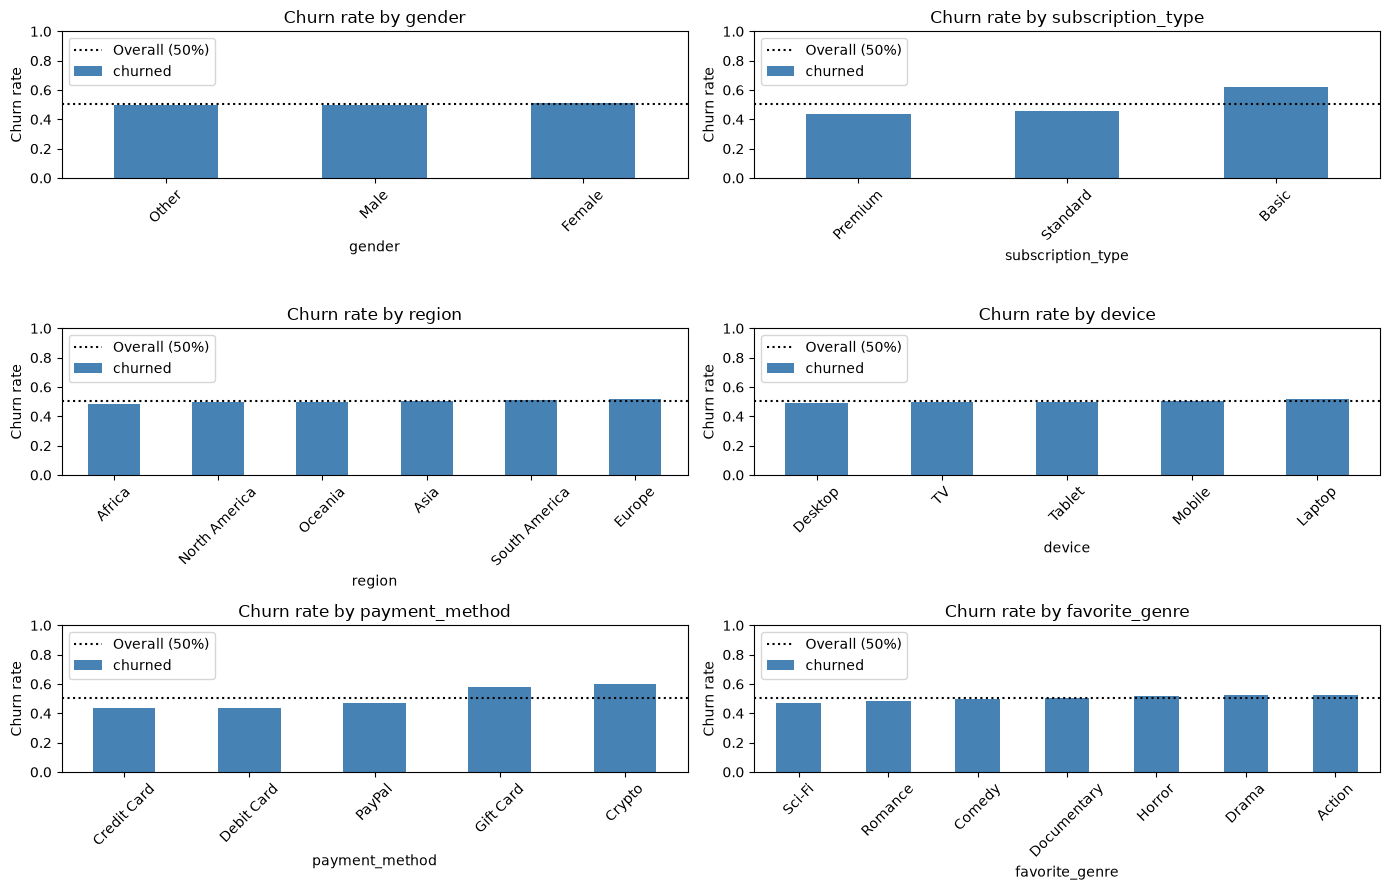

             Feature  Chi-square       p-value  Cramers V  Degrees of Freedom
1  subscription_type  133.277842  1.145735e-29   0.163265                   2
4     payment_method   96.906921  4.478433e-20   0.139217                   4
5     favorite_genre    6.970424  3.235910e-01   0.037337                   6
2             region    2.654240  7.531078e-01   0.023040                   5
3             device    1.446023  8.361579e-01   0.017006                   4
0             gender    0.650110  7.224877e-01   0.011403                   2
             Feature  Chi-square       p-value  Cramers V  Degrees of Freedom
1  subscription_type  133.277842  1.145735e-29   0.163265                   2
4     payment_method   96.906921  4.478433e-20   0.139217                   4
5     favorite_genre    6.970424  3.235910e-01   0.037337                   6
2             region    2.654240  7.531078e-01   0.023040                   5
3             device    1.446023  8.361579e-01   0.017006       

In [16]:
overall_churn = y.mean()

plt.figure(figsize=(14, 9))
for i, col in enumerate(categorical_columns, 1):
    plt.subplot(3, 2, i)
    churn_rate = y.groupby(X_cat[col], observed=True).mean().sort_values()
    churn_rate.plot(kind='bar', color='steelblue')
    plt.axhline(overall_churn, color='black', linestyle=':', label=f'Overall ({overall_churn:.0%})')
    plt.ylim(0, 1)
    plt.ylabel('Churn rate')
    plt.title(f'Churn rate by {col}')
    plt.xticks(rotation=45)
    plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Chi-square test for categorical features
from scipy.stats import chi2_contingency
import numpy as np

chi_results = []

for col in categorical_columns:

    contingency_table = pd.crosstab(
        X_cat[col].fillna('Missing'),
        y
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.values.sum()
    r, c = contingency_table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    chi_results.append({
        'Feature': col,
        'Chi-square': chi2,
        'p-value': p_value,
        'Cramers V': cramers_v,
        'Degrees of Freedom': dof
    })

chi_results = pd.DataFrame(chi_results)

chi_results = chi_results.sort_values(
    'Cramers V',
    ascending=False
)

print(chi_results)

print(chi_results)
print(categorical_summary)
plt.show()


Do subscription type and payment method add new information?

Maybe Basic customers churn more simply because they watch less. In that case `subscription_type` would add nothing that `avg_watch_time_per_day` doesn't already tell us.

To check this, we split customers into low watchers (≤ 0.5 hours per day, where most churn happens) and high watchers, and compare churn rates within each group. If the differences between categories remain *within* a group, the feature adds new information.

We also check whether the two features are related to each other, and whether watch time differs between subscription tiers.

In [17]:
watch_group = pd.Series(
    np.where(X['avg_watch_time_per_day'] <= 0.5, 'Low watcher (<= 0.5 h/day)', 'High watcher (> 0.5 h/day)'),
    index=X.index,
    name='watch_group'
)

for col in ['subscription_type', 'payment_method']:
    table = pd.crosstab(watch_group, X_cat[col], values=y, aggfunc='mean')
    print(f'Churn rate by {col}, within each watch-time group:')
    print(table.round(2), '\n')

# Are the two features related to each other?
# If every row looks roughly the same, they are independent
print('Share of payment methods within each subscription type:')
print(pd.crosstab(X_cat['subscription_type'], X_cat['payment_method'], normalize='index').round(2), '\n')

# Do subscription tiers differ in viewing behaviour?
print('Median viewing behaviour per subscription type:')
print(X.groupby('subscription_type', observed=True)[['watch_hours', 'last_login_days', 'avg_watch_time_per_day']].median())

Churn rate by subscription_type, within each watch-time group:
subscription_type           Basic  Premium  Standard
watch_group                                         
High watcher (> 0.5 h/day)   0.04     0.00      0.00
Low watcher (<= 0.5 h/day)   0.92     0.66      0.68 

Churn rate by payment_method, within each watch-time group:
payment_method              Credit Card  Crypto  Debit Card  Gift Card  PayPal
watch_group                                                                   
High watcher (> 0.5 h/day)         0.01    0.03        0.01       0.02    0.02
Low watcher (<= 0.5 h/day)         0.67    0.88        0.66       0.86    0.69 

Share of payment methods within each subscription type:
payment_method     Credit Card  Crypto  Debit Card  Gift Card  PayPal
subscription_type                                                    
Basic                     0.21    0.18        0.20       0.19    0.22
Premium                   0.19    0.21        0.21       0.20    0.19
Standard 

Findings:

- Only `subscription_type` and `payment_method` clearly differ from the overall churn rate. Basic customers churn more (62% vs 44–45%), and so do customers paying with Crypto or a Gift Card (58–60% vs 44–47%).
- These features are not just   When splitting Among low watchers, Basic customers churn 92% of the time vs 66–68% for Standard and Premium, and Crypto or Gift Card payers 86–88% vs 66–69% for the other methods. So both features add information beyond viewing behaviour.
- The two features are independent of each other, and all tiers have about the same median watch time.

Decision: keep `subscription_type` and `payment_method`, and drop gender, region, device and favourite genre. Idea for data preparation: Crypto and Gift Card behave the same (both prepaid, more anonymous payment methods), so they could be combined into one feature.